<h1><b>DAT540: Introduction to Data Science</b></h1><h2><b>Project Topic:</b> Predicting Gallstone Disease from Clinical and Bioimpedance Data</h2>
    <p>
        In this notebook, we will explore the clinical dataset from the <b>Internal Medicine Outpatient Clinic of Ankara VM Medical Park Hospital</b> to experiment with how machine learning can be used to predict gallstone disease using <b>non-imaging features</b>.
    </p>
    <p><b>Link to dataset:</b> <a href="https://archive.ics.uci.edu/dataset/1150/gallstone-1" target="_blank" rel="noopener noreferrer">https://archive.ics.uci.edu/dataset/1150/gallstone-1</a></p>




Group project(14) with other 4 students 




<h2><b>Objective:</b> Predict gallstone status (Yes/No) from clinical + bioimpedance features</h2>

This notebook is structured as followed 🇰
1. Initial Data Review (load dataset, shape, info etc.)
2. Data cleaning
3. Data exploration and Visualization
4. Data Preprocessing and feature selection
5. Model Training and performance
6. Validation and Evaluation
7. Conclusion

In [44]:
# We used google collab, so in order to load the dataset, we first need to mount the drive.
# import the google drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
# import all the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import GridSearchCV



Step 1 :  Initial Data Review
1. Load the dataset
2. Check the shape of the dataset
3. Information of the dataset (feature names , data types )
4. Check for missing values and duplicates
5. Basic statistics overview


In [46]:
# get the file_path of the dataset.
file_path = "/content/drive/MyDrive/Data Science Project - 2025 /dataset-uci.csv"

In [47]:
# diaplay the dataset in a pandas dataframe
df = pd.read_csv(file_path)
df.head(5) # diaplay the first 5


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [48]:
# get the shape of the dataset
df.shape

(319, 39)

In [49]:
# get the information of the dataset ( feature names, missing value count and data type)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                     

In [50]:
# check for missing values
if df.isnull().values.any():
  print("There are missing values in the dataset.")
else:
  print("There are no missing values in the dataset.")


There are no missing values in the dataset.


In [51]:
# Check for duplicate rows and columns

duplicate_rows = df.duplicated().sum()
duplicate_collumns = df.T.duplicated().sum()
print("Duplciate rows: ", duplicate_rows)
print("Duplicate columns: ", duplicate_collumns)

Duplciate rows:  0
Duplicate columns:  0


In [52]:
# Quick summary of the data
df.describe()

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
count,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.00000,319.000000,...,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000
mean,0.495298,48.068966,0.492163,0.335423,0.037618,0.028213,0.025078,0.134796,167.15674,80.564890,...,49.475549,144.502163,21.684953,26.855799,73.112539,0.800611,100.818903,1.853856,14.418182,21.401411
std,0.500763,12.114558,0.500724,0.517340,0.190568,0.165841,0.156609,0.342042,10.05303,15.709069,...,17.718701,97.904493,16.697605,27.884413,24.181069,0.176433,16.971396,4.989591,1.775815,9.981659
min,0.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,145.00000,42.900000,...,25.000000,1.390000,8.000000,3.000000,7.000000,0.460000,10.600000,0.000000,8.500000,3.500000
25%,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,159.50000,69.600000,...,40.000000,83.000000,15.000000,14.250000,58.000000,0.650000,94.170000,0.000000,13.300000,13.250000
50%,0.000000,49.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,168.00000,78.800000,...,46.500000,119.000000,18.000000,19.000000,71.000000,0.790000,104.000000,0.215000,14.400000,22.000000
75%,1.000000,56.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,175.00000,91.250000,...,56.000000,172.000000,23.000000,30.000000,86.000000,0.920000,110.745000,1.615000,15.700000,28.060000
max,1.000000,96.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,191.00000,143.500000,...,273.000000,838.000000,195.000000,372.000000,197.000000,1.460000,132.000000,43.400000,18.800000,53.100000


Observation from Initial Data Review:

The dataset contains records of 319 patients with 39 features each, including demographic, clinical, and bioimpedance measurements. There are no missing values or duplicate entries, indicating a clean dataset. The target variable, Gallstone Status, is nearly balanced with approximately 49.5% positive cases. Feature distributions show a wide range of values, with some features such as Glucose, Triglyceride, AST, and ALT exhibiting high maximum values relative to their means and medians, suggesting the presence of outliers or skewed distributions that may require further investigation during preprocessing.



Step 2 : Data Cleaning

Typically, this step involves handling missing values by either removing them or imputing appropriate replacements, as well as eliminating duplicate records. However, as observed in Step 1, our dataset is complete—containing no missing values or duplicates. Additionally, after reviewing the data types, no conversions or encodings are necessary. For example, categorical features like Gender (F/M) and the target variable (Gallstone Status: Yes/No) are already properly encoded for modeling purposes.

Step 3 : Exploratory Analysis and Visualization

In this step we are going to cover the following:
1. Visulize features such as Gallstone Status, Gender and observe the distribution,.
2. Observe the correlation of the features and visualize the top 3 features that are highly correlated.  
3. Feature importance selection using ANOVA, create a new dataframe with the selected features only.



Correlation between Gallstone Status and other columns:
 Gallstone Status                                  1.000000
Vitamin D                                         0.354873
C-Reactive Protein (CRP)                          0.281995
Lean Mass (LM) (%)                                0.225749
Total Body Fat Ratio (TBFR) (%)                   0.225470
Bone Mass (BM)                                    0.216570
Hemoglobin (HGB)                                  0.196872
Extracellular Water (ECW)                         0.178436
Total Fat Content (TFC)                           0.170158
Extracellular Fluid/Total Body Water (ECF/TBW)    0.169826
Hyperlipidemia                                    0.161901
High Density Lipoprotein (HDL)                    0.158622
Gender                                            0.153483
Visceral Fat Area (VFA)                           0.140397
Aspartat Aminotransferaz (AST)                    0.134910
Creatinine                                        0.132283

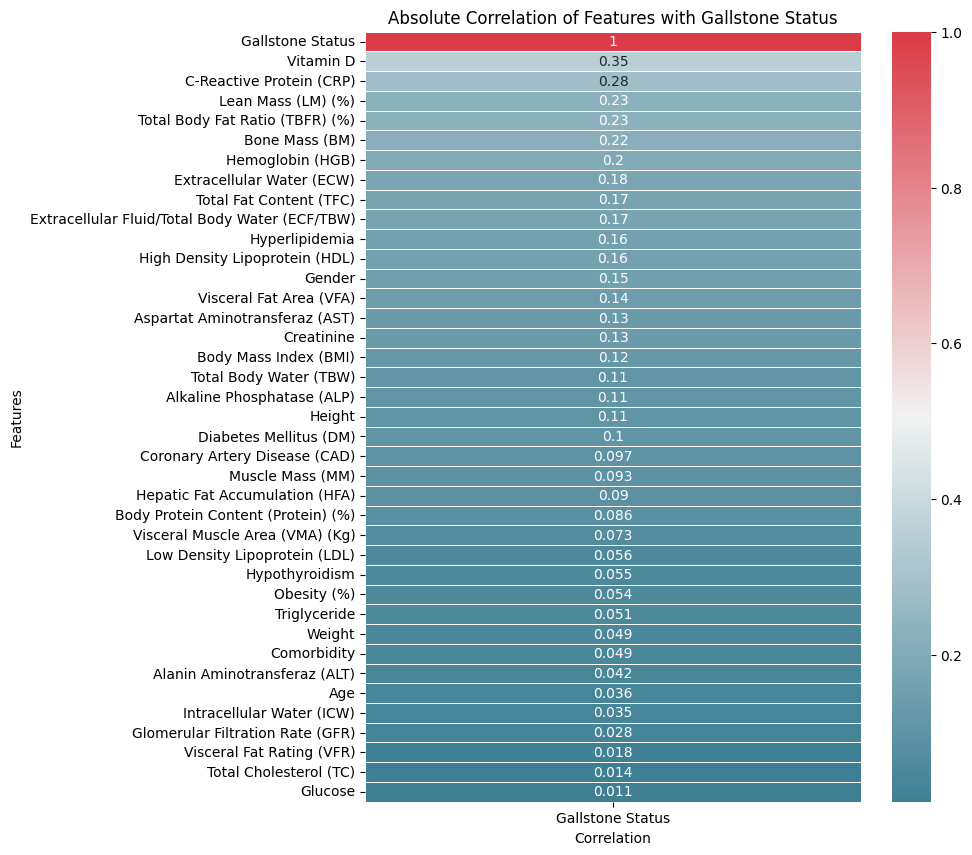

In [53]:
# Correlation between gallstone status vs all features

# Compute absolute correlation values of all columns with 'Gallstone Status'
correlations = df.corr().iloc[0].abs()

# Sort correlations in descending order
sorted_corr = correlations.sort_values(ascending=False)

print("Correlation between Gallstone Status and other columns:\n", sorted_corr)

# Visualize correlations as a heatmap
plt.figure(figsize=(8, 10))
colormap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(sorted_corr.to_frame(), annot=True, cmap= colormap, cbar=True, linewidths=0.5)
plt.title('Absolute Correlation of Features with Gallstone Status')
plt.ylabel('Features')
plt.xlabel('Correlation')
plt.show()


Top Correlated Features:

1. Vitamin D (0.355): Shows the strongest correlation with gallstone status, indicating it might be an important predictor.
2. C-Reactive Protein (CRP) (0.282): An inflammation marker, moderately correlated, likely relevant clinically.
3. Lean Mass, Total Body Fat Ratio, Bone Mass, Hemoglobin, and others (~0.17 - 0.23): These body composition and blood parameters have moderate correlation and may contribute useful information.

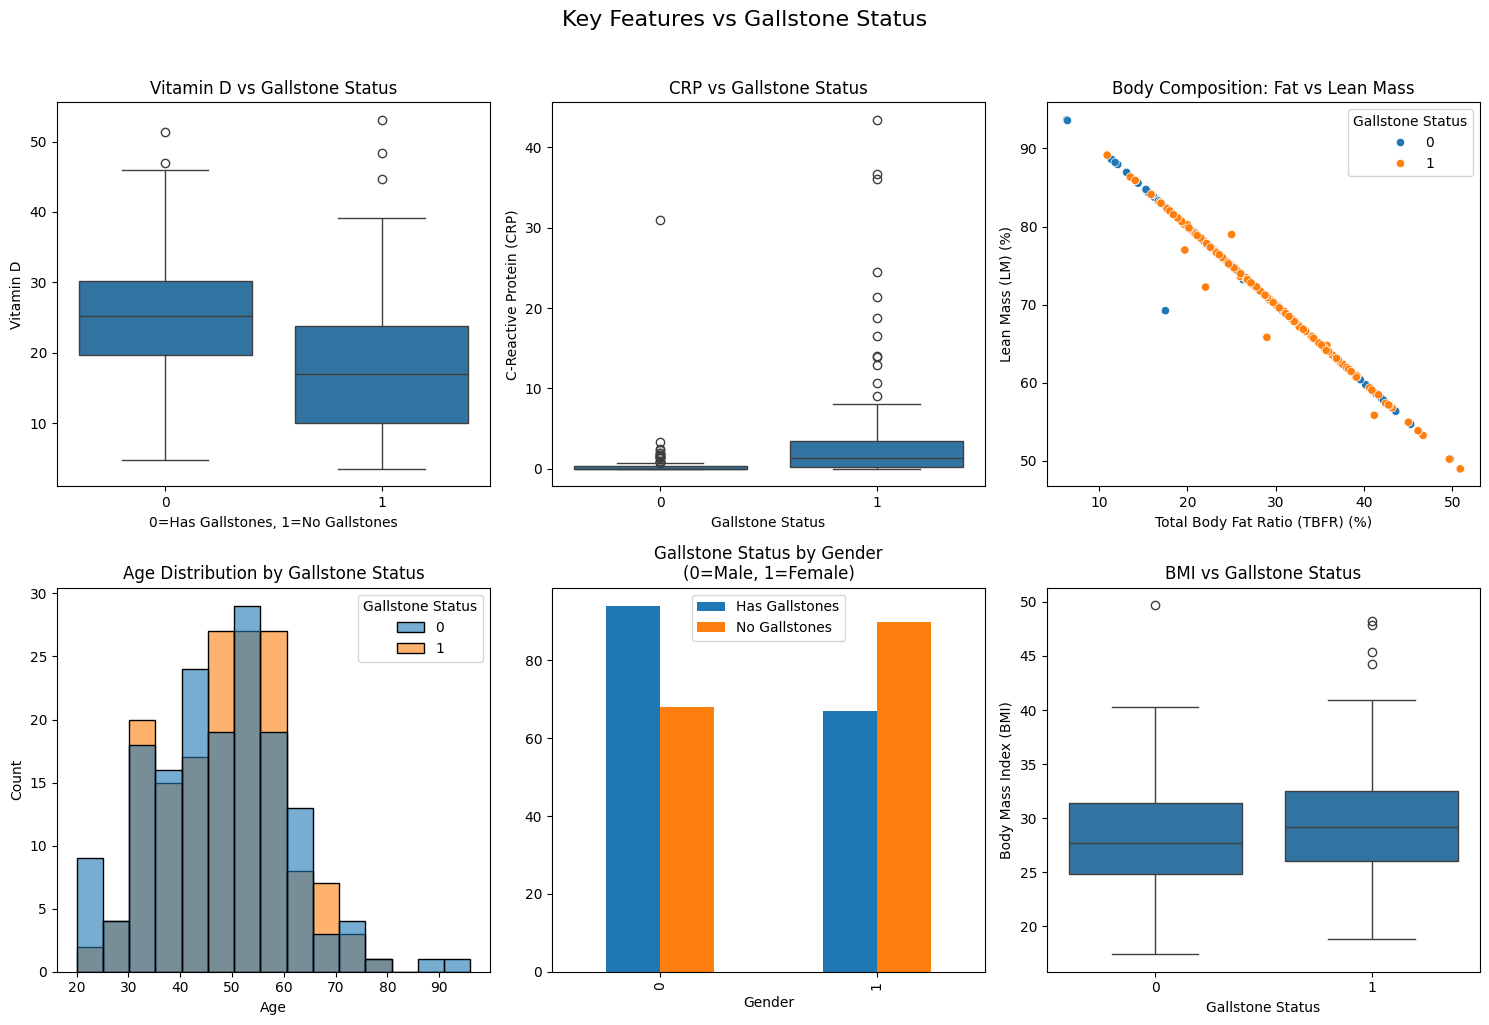

In [54]:
# Create subplots for the top features
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Key Features vs Gallstone Status', fontsize=16, y=1.02)

# 1. Vitamin D (strongest predictor)
sns.boxplot(x='Gallstone Status', y='Vitamin D', data=df, ax=axes[0,0])
axes[0,0].set_title('Vitamin D vs Gallstone Status')
axes[0,0].set_xlabel('0=Has Gallstones, 1=No Gallstones')

# 2. CRP
sns.boxplot(x='Gallstone Status', y='C-Reactive Protein (CRP)', data=df, ax=axes[0,1])
axes[0,1].set_title('CRP vs Gallstone Status')

# 3. Lean Mass vs Body Fat Ratio (they're complementary)
sns.scatterplot(x='Total Body Fat Ratio (TBFR) (%)', y='Lean Mass (LM) (%)',
                hue='Gallstone Status', data=df, ax=axes[0,2])
axes[0,2].set_title('Body Composition: Fat vs Lean Mass')

# 4. Age distribution by gallstone status
sns.histplot(data=df, x='Age', hue='Gallstone Status', multiple="layer",
             alpha=0.6, ax=axes[1,0])
axes[1,0].set_title('Age Distribution by Gallstone Status')

# 5. Gender analysis
gender_gallstone = pd.crosstab(df['Gender'], df['Gallstone Status'])
gender_gallstone.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Gallstone Status by Gender\n(0=Male, 1=Female)')
axes[1,1].legend(['Has Gallstones', 'No Gallstones'])

# 6. BMI vs Gallstone Status
sns.boxplot(x='Gallstone Status', y='Body Mass Index (BMI)', data=df, ax=axes[1,2])
axes[1,2].set_title('BMI vs Gallstone Status')

plt.tight_layout()
plt.show()

1. Vitamin D vs Gallstone Status (Top-left):

Patients without gallstones (label 1) tend to have lower Vitamin D levels compared to those with gallstones (label 0).
The median Vitamin D level is noticeably higher in the gallstone group, but there is considerable overlap and variability.
This suggests Vitamin D may have an association with gallstone presence, but it is not definitive on its own.

2. C-Reactive Protein (CRP) vs Gallstone Status (Top-center):

CRP levels are generally higher in patients with gallstones, indicating increased inflammation in this group.
The distribution is skewed with many low values, but several outliers with very high CRP exist in the gallstone group.
CRP appears to be a meaningful marker related to gallstone disease.

3. Body Composition: Fat vs Lean Mass (Top-right):

There is a strong inverse linear relationship between Total Body Fat Ratio (TBFR) and Lean Mass (LM) as expected (more fat means less lean mass).
Patients with gallstones (orange dots) tend to cluster towards higher fat ratios and lower lean mass compared to those without gallstones (blue dots).
This indicates body composition differences may relate to gallstone risk.

4. Age Distribution by Gallstone Status (Bottom-left):

The age distributions of patients with and without gallstones largely overlap with similar peaks around 45-55 years.
There is no clear age group that distinctly separates the two groups, suggesting age alone is not a strong discriminator.

5. Gallstone Status by Gender (Bottom-center):

Males (0) have a higher count of gallstone cases compared to females (1).
Conversely, females have more patients without gallstones.
This gender difference supports the idea that gallstone prevalence varies by gender in this cohort.

6. BMI vs Gallstone Status (Bottom-right):

The median BMI is slightly higher in patients with gallstones, though distributions overlap substantially.
Some outliers with very high BMI exist in both groups.
BMI may contribute as a risk factor but is not a definitive predictor alone.


Vitamin D and CRP show meaningful differences between gallstone groups, indicating their potential as important predictors.
Body composition (fat vs lean mass) clearly differs by gallstone status, highlighting metabolic factors.
Age and BMI show overlapping distributions, suggesting limited discriminatory power alone.
Gender differences exist and may influence gallstone risk.

To evaluate the importance of the features we decided to use nalysis of Variance technique also known as ANOVA. Higher F scores suggests a feature that has a greater discriminative power i.e it can distinguish between instances with gallstones more effectively.

In [55]:
# Referencing the paper, we also decided to utilize ANOVA feature importance

X = df.drop(columns=['Gallstone Status'])  # Features
y = df['Gallstone Status']                  # Target

# If you have categorical features, encode them appropriately before this step

# Compute ANOVA F-values and p-values
F_values, p_values = f_classif(X, y)

# Create a DataFrame for better visualization
anova_results = pd.DataFrame({
    'Feature': X.columns,
    'F_value': F_values,
    'p_value': p_values
})

# Sort by F_value descending
anova_results = anova_results.sort_values(by='F_value', ascending=False)

print(anova_results)

                                           Feature    F_value       p_value
37                                       Vitamin D  45.673154  6.709802e-11
35                        C-Reactive Protein (CRP)  27.385949  3.037234e-07
15                              Lean Mass (LM) (%)  17.022706  4.725017e-05
14                 Total Body Fat Ratio (TBFR) (%)  16.978389  4.830830e-05
18                                  Bone Mass (BM)  15.599719  9.649236e-05
36                                Hemoglobin (HGB)  12.781941  4.045010e-04
11                       Extracellular Water (ECW)  10.425070  1.373387e-03
21                         Total Fat Content (TFC)   9.451995  2.292569e-03
13  Extracellular Fluid/Total Body Water (ECF/TBW)   9.414047  2.339084e-03
5                                   Hyperlipidemia   8.532832  3.738263e-03
28                  High Density Lipoprotein (HDL)   8.181862  4.511971e-03
1                                           Gender   7.647763  6.017412e-03
22          

The ANOVA F-test results indicate that features like Vitamin D, C-Reactive Protein (CRP), Lean Mass, and Total Body Fat Ratio have the strongest association with gallstone status, exhibiting high F-values and statistically significant p-values. Many other features show moderate to low F-values, suggesting weaker relationships with the target variable. To focus on the most relevant predictors, we will drop all features with an F-value less than 0.70 from our dataset before proceeding with modeling.

In [56]:
# Filter features with F_value >= 0.70
selected_features = anova_results[anova_results['F_value'] >= 0.70]['Feature'].tolist()

print("Selected features (F_value >= 0.70):")
print(selected_features)

# Create a new DataFrame with only selected features
X_selected = X[selected_features]

# If you want, you can concatenate the target back for further processing
df_selected = pd.concat([X_selected, y], axis=1)

Selected features (F_value >= 0.70):
['Vitamin D', 'C-Reactive Protein (CRP)', 'Lean Mass (LM) (%)', 'Total Body Fat Ratio (TBFR) (%)', 'Bone Mass (BM)', 'Hemoglobin (HGB)', 'Extracellular Water (ECW)', 'Total Fat Content (TFC)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Hyperlipidemia', 'High Density Lipoprotein (HDL)', 'Gender', 'Visceral Fat Area (VFA)', 'Aspartat Aminotransferaz (AST)', 'Creatinine', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Alkaline Phosphatase (ALP)', 'Height', 'Diabetes Mellitus (DM)', 'Coronary Artery Disease (CAD)', 'Muscle Mass (MM)', 'Hepatic Fat Accumulation (HFA)', 'Body Protein Content (Protein) (%)', 'Visceral Muscle Area (VMA) (Kg)', 'Low Density Lipoprotein (LDL)', 'Hypothyroidism', 'Obesity (%)', 'Triglyceride', 'Weight', 'Comorbidity']


In [57]:
df_selected.shape # 7 features were dropped

(319, 32)

Step 5 : Model Traning and Performance

1. Split the dataset ( 70% training , 30 % testing)
2. Apply machine learning models : KNN, Decision Tree, Random Forest, Logistic Regression, SVM, Gradient Boost.
3. Evaluation Metrics : Accuracy, F1 Score, Recall, Precision


In [58]:
X = df_selected.drop(columns=['Gallstone Status'])
y = df_selected['Gallstone Status']

# Split data: 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Initialize models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# Create a pipeline with scaling + logistic regression
logreg_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)


models["Logistic Regression"] = logreg_pipeline

# Then run the training and evaluation loop again
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"--- {name} Classification Report ---")
    print(classification_report(y_test, y_pred))

--- K-Nearest Neighbors Classification Report ---
              precision    recall  f1-score   support

           0       0.52      0.67      0.59        48
           1       0.54      0.40      0.46        48

    accuracy                           0.53        96
   macro avg       0.53      0.53      0.52        96
weighted avg       0.53      0.53      0.52        96

--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        48
           1       0.77      0.77      0.77        48

    accuracy                           0.77        96
   macro avg       0.77      0.77      0.77        96
weighted avg       0.77      0.77      0.77        96

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.82      0.77      0.80        48
           1       0.78      0.83      0.81        48

    accuracy                           0.80 

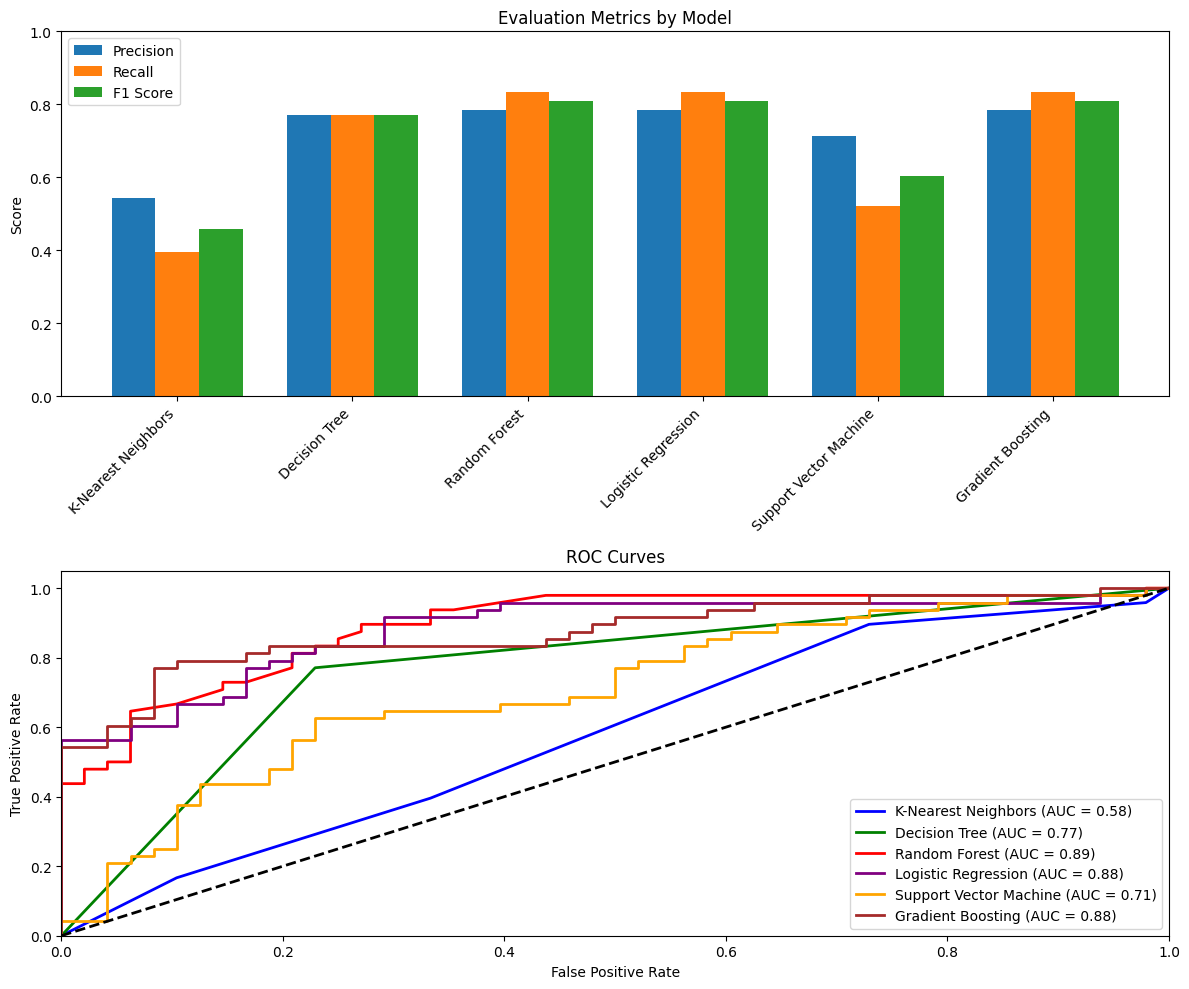

In [59]:
# Prepare containers for metrics
model_names = []
precision_scores = []
recall_scores = []
f1_scores = []
auc_scores = []

plt.figure(figsize=(12, 10))

# Colors for ROC curves
colors = ['blue', 'green', 'red', 'purple', 'orange', 'brown']

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)

    # For ROC curve, get prediction probabilities or decision function
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_scores = model.decision_function(X_test)
    else:
        # If no probability or decision function, skip ROC for this model
        y_scores = None

    # Calculate Precision, Recall, F1
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    model_names.append(name)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

    # Calculate AUC if scores available
    if y_scores is not None:
        fpr, tpr, _ = roc_curve(y_test, y_scores)  # Use y_test directly since already binary
        roc_auc = auc(fpr, tpr)
        auc_scores.append(roc_auc)

        # Plot ROC curve
        plt.subplot(2, 1, 2)
        plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'{name} (AUC = {roc_auc:.2f})')
    else:
        auc_scores.append(np.nan)

# Plot bar chart for Precision, Recall, F1
x = np.arange(len(model_names))
width = 0.25

plt.subplot(2, 1, 1)
plt.bar(x - width, precision_scores, width, label='Precision')
plt.bar(x, recall_scores, width, label='Recall')
plt.bar(x + width, f1_scores, width, label='F1 Score')

plt.xticks(x, model_names, rotation=45, ha='right')
plt.ylabel('Score')
plt.title('Evaluation Metrics by Model')
plt.ylim([0, 1])
plt.legend()

# Finalize ROC plot
plt.subplot(2, 1, 2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

Step 6 : Validation and Evaluation

1. Hyper-parameter Tuning using Grid Search
2. Evaluation of results before and after hyper-parameter tuning


In [60]:
# Define parameter grids for each model
param_grids = {
    "K-Nearest Neighbors": {
        'n_neighbors': [3, 5, 7, 9],
        'weights': ['uniform', 'distance']
    },
    "Decision Tree": {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10]
    },
    "Random Forest": {
        'n_estimators': [50, 100],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    "Logistic Regression": {
        'logisticregression__C': [0.01, 0.1, 1, 10],
        'logisticregression__solver': ['lbfgs'],
        'logisticregression__max_iter': [5000]
    },
    "Support Vector Machine": {
        'svc__C': [0.1, 1, 10],
        'svc__kernel': ['linear', 'rbf'],
        'svc__probability': [True]  # enable probability for ROC
    },
    "Gradient Boosting": {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5]
    }
}


In [61]:
# Prepare containers for results
model_names = []
precision_scores = []
recall_scores = []
f1_scores = []
auc_scores = []

base_models = {
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('logisticregression', LogisticRegression(random_state=42))
    ]),
    "Support Vector Machine": Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(random_state=42))
    ]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# Split data
X = df_selected.drop(columns=['Gallstone Status'])
y = df_selected['Gallstone Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


In [62]:
for name in base_models.keys():
    print(f"Running Grid Search for {name}...")
    model = base_models[name]
    param_grid = param_grids.get(name, {})

    grid = GridSearchCV(model, param_grid, cv=5, scoring='f1', n_jobs=-1)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    # Get prediction scores for ROC
    if hasattr(best_model, "predict_proba"):
        y_scores = best_model.predict_proba(X_test)[:, 1]
    elif hasattr(best_model, "decision_function"):
        y_scores = best_model.decision_function(X_test)
    else:
        y_scores = None

    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

    model_names.append(name)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

    if y_scores is not None:
        fpr, tpr, _ = roc_curve(y_test, y_scores)
        roc_auc = auc(fpr, tpr)
        auc_scores.append(roc_auc)
    else:
        auc_scores.append(np.nan)

    print(f"Best params for {name}: {grid.best_params_}")
    print(f"Classification report for {name}:\n{classification_report(y_test, y_pred)}\n")



Running Grid Search for K-Nearest Neighbors...
Best params for K-Nearest Neighbors: {'n_neighbors': 9, 'weights': 'distance'}
Classification report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.54      0.62      0.58        48
           1       0.55      0.46      0.50        48

    accuracy                           0.54        96
   macro avg       0.54      0.54      0.54        96
weighted avg       0.54      0.54      0.54        96


Running Grid Search for Decision Tree...
Best params for Decision Tree: {'max_depth': 10, 'min_samples_split': 2}
Classification report for Decision Tree:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        48
           1       0.77      0.77      0.77        48

    accuracy                           0.77        96
   macro avg       0.77      0.77      0.77        96
weighted avg       0.77      0.77      0.77        96


Running Grid Sea

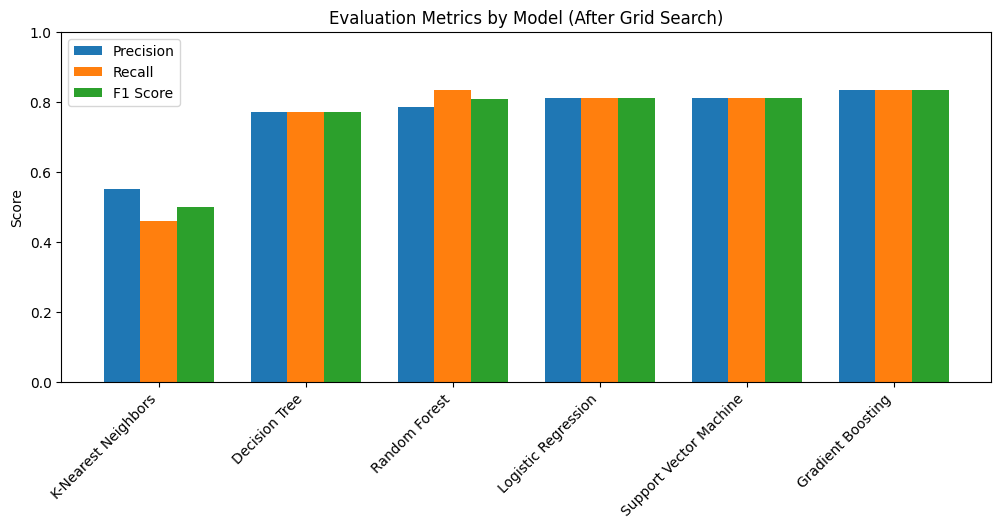

In [63]:
# Plot evaluation metrics
x = np.arange(len(model_names))
width = 0.25
colors = ['blue', 'green', 'red', 'purple', 'orange', 'brown']

plt.figure(figsize=(12, 10))

plt.subplot(2, 1, 1)
plt.bar(x - width, precision_scores, width, label='Precision')
plt.bar(x, recall_scores, width, label='Recall')
plt.bar(x + width, f1_scores, width, label='F1 Score')
plt.xticks(x, model_names, rotation=45, ha='right')
plt.ylabel('Score')
plt.title('Evaluation Metrics by Model (After Grid Search)')
plt.ylim([0, 1])
plt.legend()



Observation before and after hyper-parameter tuning 🇰

The Decision Tree, Random Forest, Logistic Regression, and Gradient Boosting models already showed solid performance with accuracies around 77-80%, and balanced precision, recall, and F1-scores for both classes. KNN and SVM performed worse, especially KNN with an accuracy near 53%.

Hyperparameter tuning improved most models, with Logistic Regression, SVM, and Gradient Boosting notably increasing their F1-scores and accuracy to around 81-83%. SVM showed a significant boost from 66% to 81% accuracy by tuning parameters and enabling probability estimates. Gradient Boosting achieved the best overall performance with 83% accuracy and balanced metrics.


Conclusion

Machine learning models applied to clinical and bioimpedance data effectively predicted gallstone disease status in a cohort of 319 patients. After feature selection and hyperparameter tuning, Gradient Boosting achieved the best performance with balanced accuracy and classification metrics around 83%. This study demonstrates the potential of non-imaging features combined with machine learning to support early and accurate gallstone diagnosis.